# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [25]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [26]:
df = pd.read_csv("cleaned_aviation_data.csv", low_memory=False, parse_dates=["event_date"])
df.shape

(66851, 30)

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [31]:
df["typical_aboard"] = df.groupby("plane_type")["total_aboard"].transform("median")

df["plane_size"] = df["typical_aboard"].ge(20).map({True: "large", False: "small"})

#-- A plane type is 'large' if the median number of people aboard in its accidents is 20 or more, and 'small' otherwise. 
#-- An earlier version used the maximum, but a few multi-aircraft collisions copy the whole event's injury counts onto both aircraft, which made small planes like the Piper PA-28-181 look large (max 90 aboard, median 2). 
#The median is not affected by those outliers

In [32]:
df["plane_size"].value_counts()

plane_size
small    65508
large     1343
Name: count, dtype: int64

In [33]:
df[df["plane_size"] == "large"]["make"].value_counts().head(10)

make
BOEING               829
MCDONNELL DOUGLAS    172
AIRBUS               159
EMBRAER               81
DOUGLAS               40
LOCKHEED              23
AEROSPATIALE          19
DE HAVILLAND          12
FAIRCHILD              3
CESSNA                 1
Name: count, dtype: int64

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

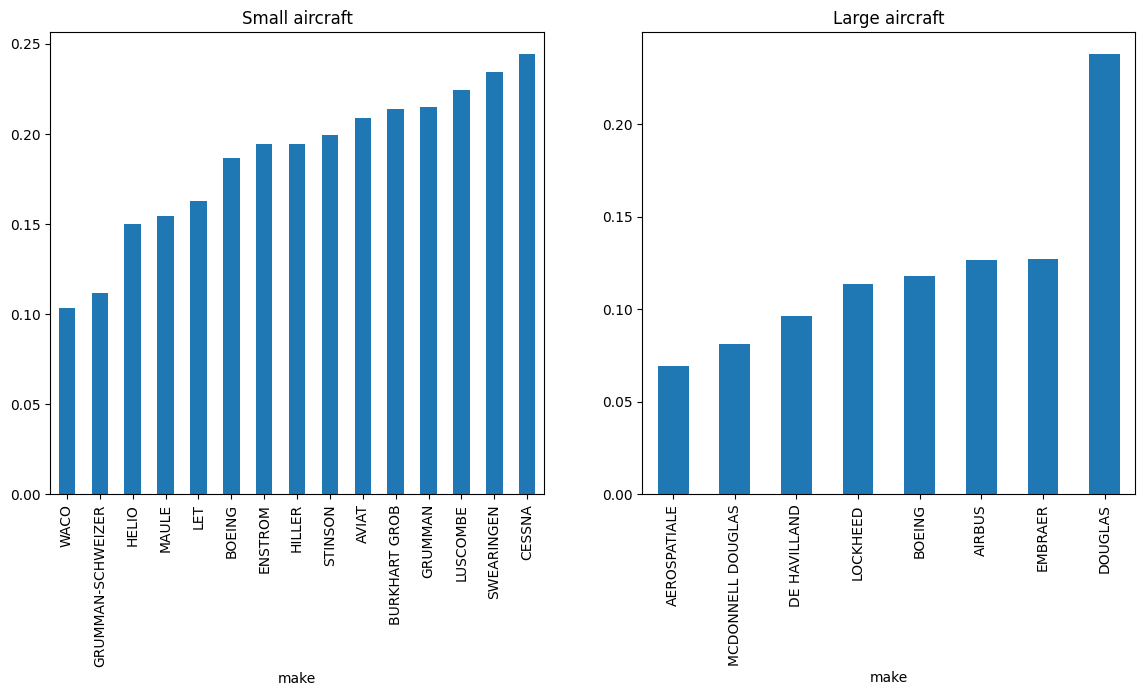

((65508, 32), (1343, 32))

In [36]:
small = df[df["plane_size"] == "small"]
large = df[df["plane_size"] == "large"]

#Calculate how many accidents have a rate and the mean of fatal/serious accidents per make
small_stats = small.groupby("make")["serious_fatal_rate"].agg(["count", "mean"])
large_stats = large.groupby("make")["serious_fatal_rate"].agg(["count", "mean"])

#Keep only makes with enough accidents (100 for small, 10 for large)
small_stats = small_stats[small_stats["count"] >= 100]
large_stats = large_stats[large_stats["count"] >= 10]

#Take the 15 makes with the lowest mean
small_top = small_stats.sort_values("mean").head(15)
large_top = large_stats.sort_values("mean").head(15)

#Plot the two groups side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
small_top["mean"].plot(kind="bar", ax=axes[0], title="Small aircraft")
large_top["mean"].plot(kind="bar", ax=axes[1], title="Large aircraft")
plt.show()

small_top, large_top
small.shape, large.shape

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

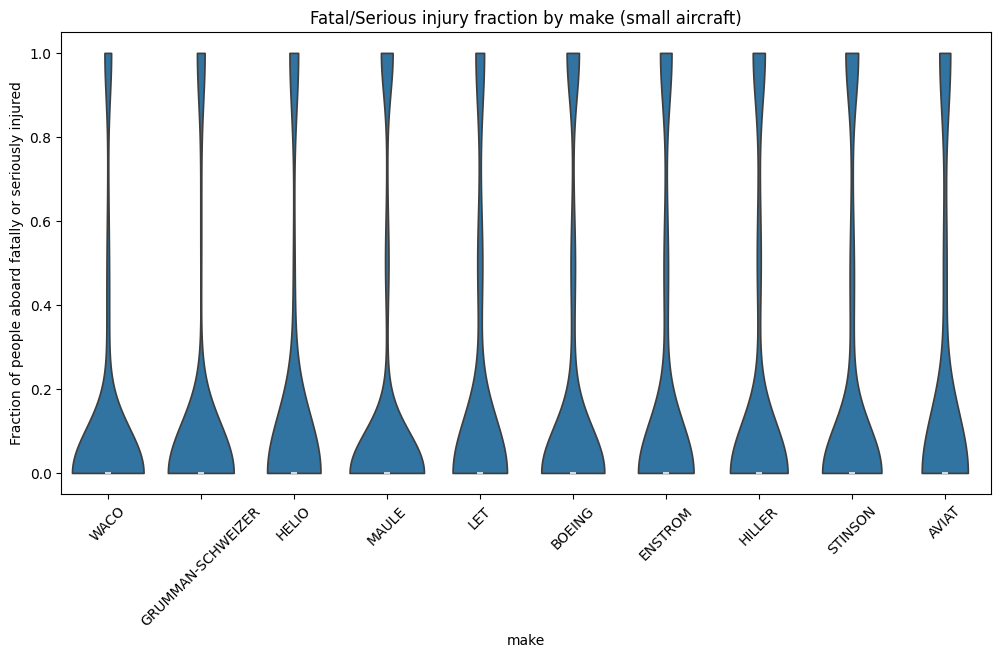

In [41]:
top10 = list(small_top.head(10).index)

subset = small[small["make"].isin(top10)]

plt.figure(figsize=(12, 6))
sns.violinplot(data=subset, x="make", y="serious_fatal_rate", order=top10, cut=0)
plt.xticks(rotation=45)
plt.title("Fatal/Serious injury fraction by make (small aircraft)")
plt.ylabel("Fraction of people aboard fatally or seriously injured")
plt.show()

#--This violinplot shows the per-accident fatal/serious fraction for the 10 small-aircraft makes with the lowest mean.

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

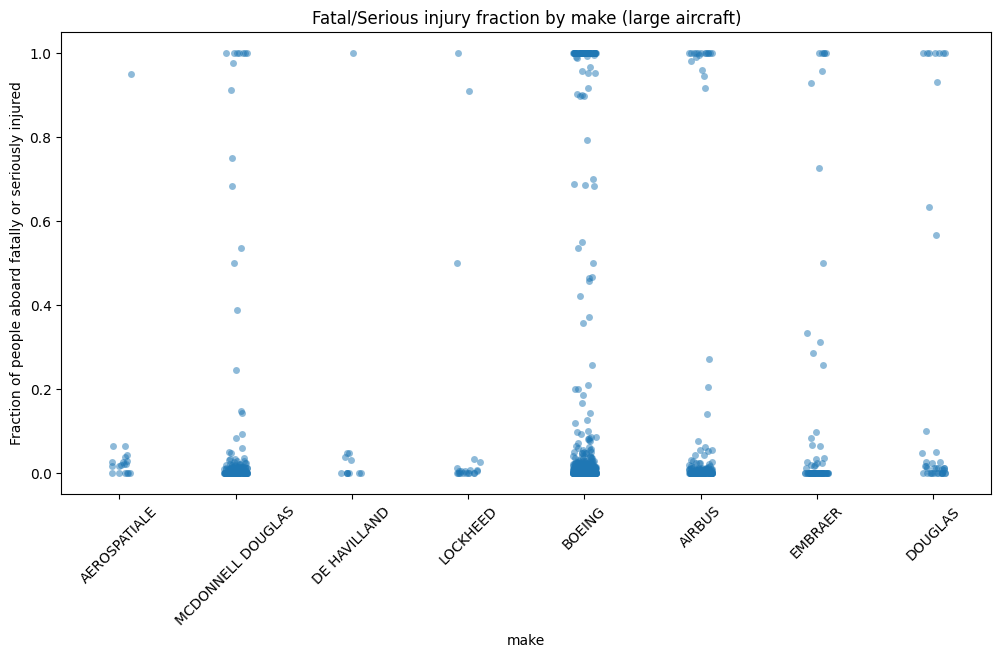

In [42]:
top_large = list(large_top.head(10).index)

subset= large[large["make"].isin(top_large)]

plt.figure(figsize=(12, 6))
sns.stripplot(data=subset, x="make", y="serious_fatal_rate", order=top_large, alpha=0.5)
plt.xticks(rotation=45)
plt.title("Fatal/Serious injury fraction by make (large aircraft)")
plt.ylabel("Fraction of people aboard fatally or seriously injured")
plt.show()

#--Each dot represents 1 accident, only 8 Large-aircraft makes with the most accidents.

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [43]:
#Calculate how many accidents have known damage levels for each make
small_destroyed = small.groupby("make")["destroyed"].agg(["count", "mean"])
large_destroyed = large.groupby("make")["destroyed"].agg(["count", "mean"])

#Keep only makes with enough accidents (100 for small, 10 for large)
small_destroyed = small_destroyed[small_destroyed["count"] >= 100]
large_destroyed = large_destroyed[large_destroyed["count"] >= 10]

#Sort from the lowest destruction rate and keep the lowest 15
small_destroyed = small_destroyed.sort_values("mean").head(15)
large_destroyed = large_destroyed.sort_values("mean").head(15)

large_destroyed["margin"] = (1 / large_destroyed["count"] ** 0.5).round(2)

small_destroyed, large_destroyed

#-- Small aircraft: LET, Aviat, Waco, and Maule have the lowest destruction rates (8-9%), and several of these makes also rank in the lowest injury rates. 
#-- Some low-ranking makes are gliders. Large aircraft: Embraer, McDonnell Douglas, and Boeing have the lowest destruction rates (17-19%), but their margins overlap, so no ranking among them is claimed. 
#-- Makes with fewer than 30 accidents are weak evidence.

(               count      mean
 make                          
 LET              135  0.081481
 AVIAT            139  0.086331
 WACO             137  0.087591
 MAULE            568  0.093310
 LUSCOMBE         386  0.103627
 BURKHART GROB    120  0.108333
 SCHLEICHER       136  0.117647
 TAYLORCRAFT      364  0.123626
 HELIO            104  0.125000
 STINSON          418  0.133971
 AERONCA          604  0.139073
 BOEING           457  0.142232
 SCHWEIZER        741  0.145749
 ENSTROM          273  0.150183
 CHAMPION         500  0.152000,
                    count      mean
 make                              
 EMBRAER               48  0.166667
 MCDONNELL DOUGLAS    123  0.170732
 BOEING               465  0.191398
 LOCKHEED              18  0.222222
 AIRBUS                81  0.259259
 DOUGLAS               33  0.272727)

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [ ]:
**Small aircraft.** Seven makes rank among both the lowest destruction rates and the ten lowest fatal/serious injury fractions: Aviat, Waco, Maule, Helio, Stinson, Boeing and Enstrom. LET also ranks low on both, but its plane types are Blanik and Solo gliders, which are slow and light and not comparable to powered passenger aircraft, so I exclude it. The powered makes Maule, Aviat and Waco have destruction rates of about 9% across 137 to 568 accidents each, so I recommend them first.

**Large aircraft.** McDonnell Douglas is low on both measures (8.1% fatal/serious injury fraction and 17% destroyed, from 165 and 123 accidents), so it is the strongest large-aircraft candidate in this data. Boeing has the most evidence (758 accidents with a rate, 11.8% injury fraction, 19% destroyed). Embraer (12.7% injury fraction, 17% destroyed, 48 to 77 accidents) and Airbus (12.7% injury fraction, 26% destroyed) are close to Boeing on injuries, and the differences are within the margin of error. Douglas is the highest on both measures (23.8% injury fraction, 27% destroyed). Aerospatiale, De Havilland and Lockheed have low injury means, but each has fewer than 25 accidents, so I do not recommend any of them on this evidence.

**Statistical strength.** A rough upper bound on the margin of error for a rate is 1 divided by the square root of the number of accidents. For Embraer's 48 accidents that is at most about ±14 percentage points, and for Boeing's 465 about ±5. Differences between Boeing, Airbus and Embraer fall within these margins, so I do not rank them against each other.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.